# Query length by category

Are the query lengths different between topic categories? For PG19 and PubMed this
notebook shows, for every category:

1. **Length curve**: the cumulative distribution of query length in characters
   (share of queries at or below each length), overall and per query length bucket
   (short / medium / long).
2. **Deciles**: the 10%, 20%, ..., 90% length of each category, as a plot and a table.

Each query is counted once (the CSV repeats every query for 4 values of k and 2
iterations). The query texts are identical for every model, so smol's CSV is used.
Figures and tables are saved in `query_length_by_category/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

SOURCES = {
    "PG19": Path("revised-black-box-cat/no-cache/per_query_rag_llm_latencies_ordered_smol_pg19.csv"),
    "PubMed": Path("revised-black-box-cat/no-cache/per_query_rag_llm_latencies_ordered_smol_pubmed.csv"),
}
LENGTH_BUCKETS = ("Short", "Medium", "Long")
DECILES = np.arange(10, 100, 10)
OUTPUT_DIRECTORY = Path("query_length_by_category")
OUTPUT_DIRECTORY.mkdir(exist_ok=True)

# Categorical colours in a fixed order, plus a line style per category so the
# curves stay distinguishable without colour.
COLOURS = ("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4")
LINE_STYLES = ("-", "--", "-.", ":", (0, (5, 1, 1, 1)))
INK_SECONDARY = "#52514e"
GRID_COLOUR = "#e4e3df"
AXIS_COLOUR = "#b5b4ad"


def load_queries(path: Path) -> pd.DataFrame:
    queries = (
        pd.read_csv(path, usecols=["query_id", "query_text", "category", "length"])
        .drop_duplicates("query_id")
        .reset_index(drop=True)
    )
    queries["query_length_chars"] = queries["query_text"].astype(str).str.len()
    return queries


queries = {dataset: load_queries(path) for dataset, path in SOURCES.items()}
for dataset, frame in queries.items():
    print(f"{dataset}: {len(frame)} unique queries, {frame['category'].nunique()} categories")

PG19: 1800 unique queries, 5 categories
PubMed: 1790 unique queries, 5 categories


## 1. Length curves (cumulative distribution)

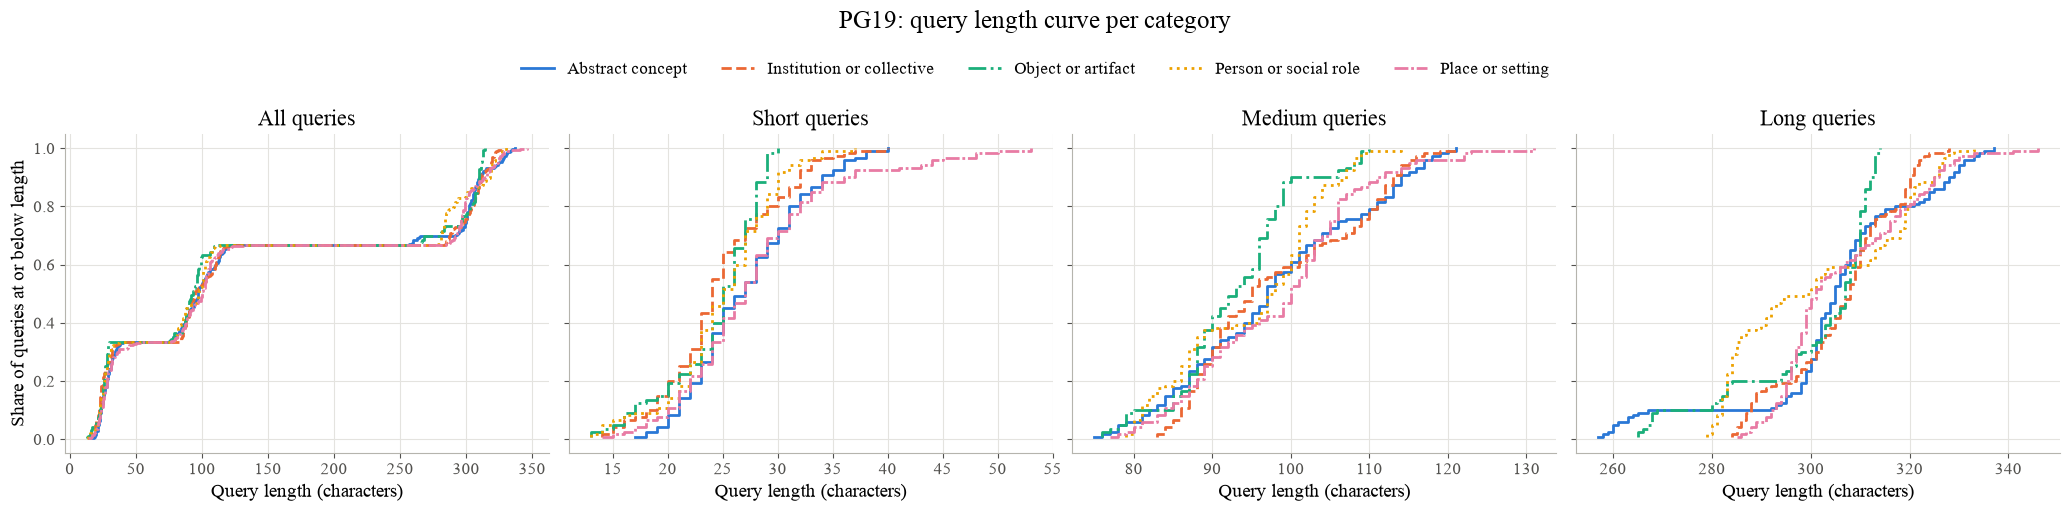

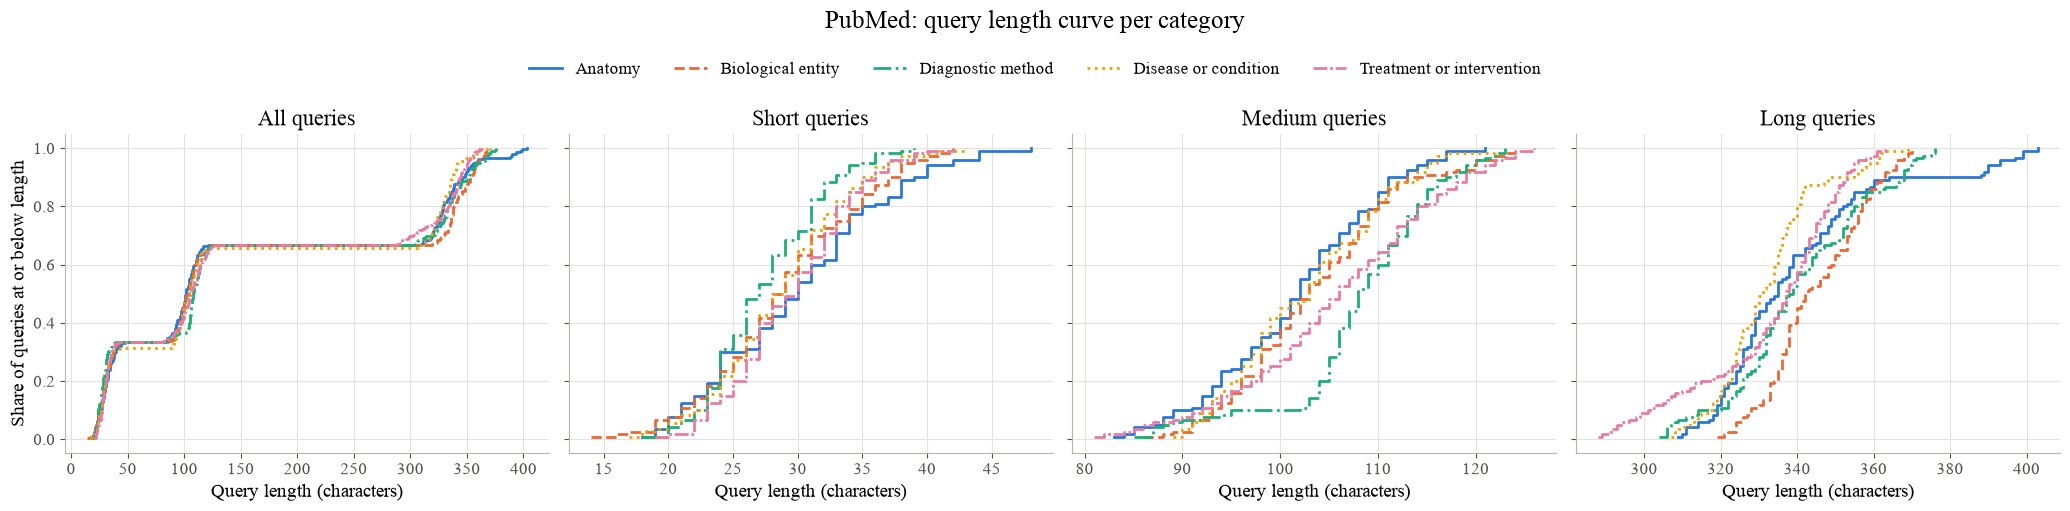

In [2]:
def style_axis(ax):
    ax.grid(color=GRID_COLOUR, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS_COLOUR)
    ax.tick_params(colors=INK_SECONDARY)


def plot_length_curves(dataset: str, frame: pd.DataFrame) -> None:
    categories = sorted(frame["category"].unique())
    panels = [("All queries", frame)] + [
        (f"{bucket} queries", frame[frame["length"] == bucket]) for bucket in LENGTH_BUCKETS
    ]
    fig, axes = plt.subplots(1, len(panels), figsize=(5.2 * len(panels), 4.6), sharey=True)
    for ax, (title, panel) in zip(axes, panels):
        for index, category in enumerate(categories):
            lengths = np.sort(panel.loc[panel["category"] == category, "query_length_chars"].to_numpy())
            share = np.arange(1, len(lengths) + 1) / len(lengths)
            ax.step(lengths, share, where="post", color=COLOURS[index],
                    linestyle=LINE_STYLES[index], linewidth=2, label=category)
        ax.set_title(title)
        ax.set_xlabel("Query length (characters)")
        style_axis(ax)
    axes[0].set_ylabel("Share of queries at or below length")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.02),
               ncol=len(categories), frameon=False, fontsize=12)
    fig.suptitle(f"{dataset}: query length curve per category", fontsize=18, y=1.1)
    fig.tight_layout()
    stem = OUTPUT_DIRECTORY / f"{dataset.lower()}_length_curves"
    fig.savefig(stem.with_suffix(".png"), dpi=300, bbox_inches="tight")
    fig.savefig(stem.with_suffix(".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(fig)


for dataset, frame in queries.items():
    plot_length_curves(dataset, frame)

## 2. Deciles per category

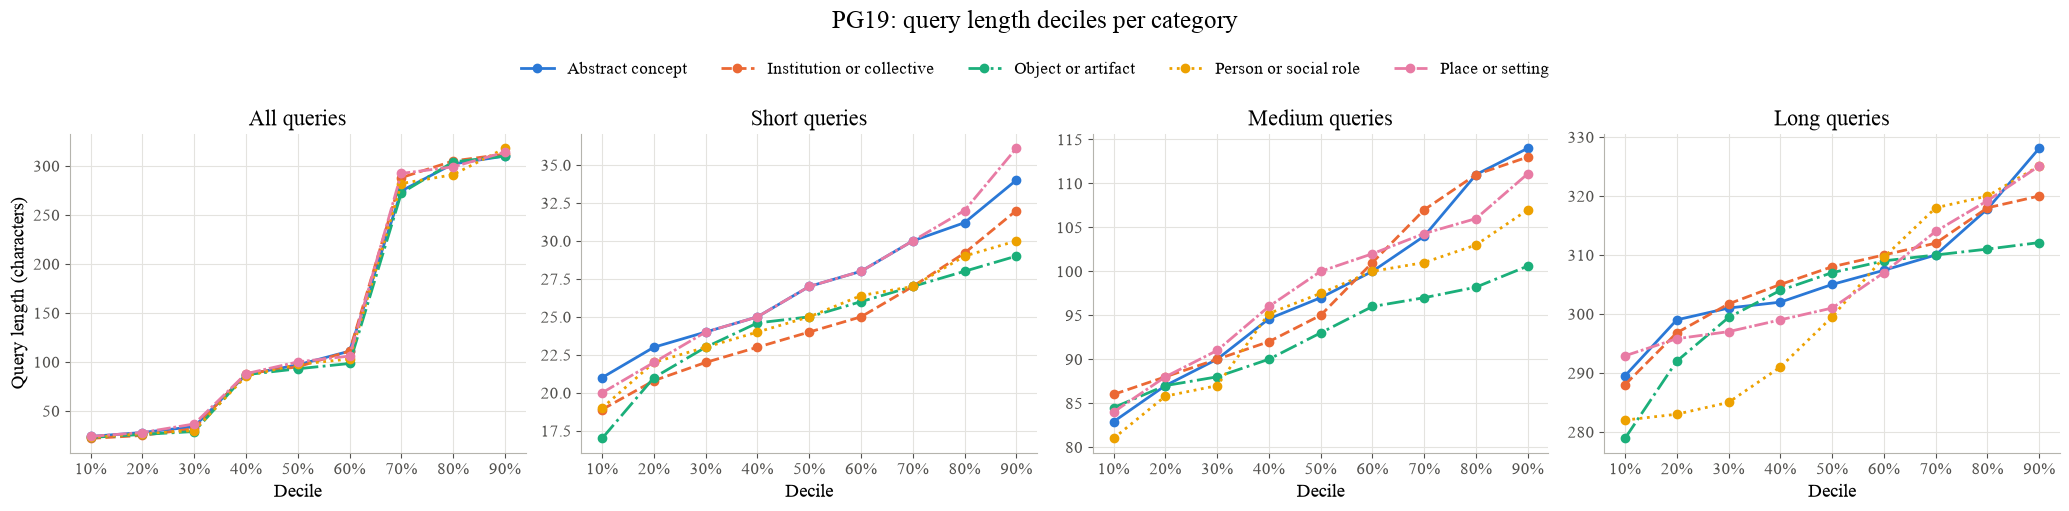

PG19: query length deciles (characters)


queries  min    p10    p20    p30  \
length bucket category                                                       
All           Abstract concept               360   17   24.0   28.0   34.0   
              Institution or collective      360   14   22.0   25.0   32.0   
              Object or artifact             360   13   23.0   26.0   29.0   
              Person or social role          360   13   23.0   26.8   30.0   
              Place or setting               360   14   24.0   28.0   36.7   
Short         Abstract concept               120   17   21.0   23.0   24.0   
              Institution or collective      120   14   18.9   20.8   22.0   
              Object or artifact             120   13   17.0   21.0   23.0   
              Person or social role          120   13   19.0   22.0   23.0   
              Place or setting               120   14   20.0   22.0   24.0   
Medium        Abstract concept               120   75   82.9   87.0   90.0   
              Institution or collective      120   83   86.0   88.0   90.0   
              Object or artifact             120   76   84.5   87.0   88.0   
              Person or social role          120   79   81.0   85.8   87.0   
              Place or setting               120   77   84.0   88.0   91.0   
Long          Abstract concept               120  257  289.5  299.0  301.0   
              Institution or collective      120  284  288.0  296.8  301.7   
              Object or artifact             120  265  278.9  292.0  299.4   
              Person or social role          120  279  282.0  283.0  285.0   
              Place or setting               120  285  292.9  295.8  297.0   

                                           p40    p50    p60    p70    p80  \
length bucket category                                                       
All           Abstract concept            87.0   97.0  111.0  274.5  302.0   
              Institution or collective   88.0   95.0  111.0  288.0  305.0   
              Object or artifact          87.0   93.0   98.4  272.3  304.0   
              Person or social role       85.6   97.5  103.0  282.0  291.0   
              Place or setting            88.0  100.0  106.0  292.3  299.0   
Short         Abstract concept            25.0   27.0   28.0   30.0   31.2   
              Institution or collective   23.0   24.0   25.0   27.0   29.2   
              Object or artifact          24.6   25.0   26.0   27.0   28.0   
              Person or social role       24.0   25.0   26.4   27.0   29.0   
              Place or setting            25.0   27.0   28.0   30.0   32.0   
Medium        Abstract concept            94.6   97.0  100.0  104.0  111.0   
              Institution or collective   92.0   95.0  101.0  107.0  111.0   
              Object or artifact          90.0   93.0   96.0   97.0   98.2   
              Person or social role       95.2   97.5  100.0  101.0  103.0   
              Place or setting            96.0  100.0  102.0  104.3  106.0   
Long          Abstract concept           302.0  305.0  307.4  310.0  317.8   
              Institution or collective  305.0  308.0  310.0  312.0  318.0   
              Object or artifact         304.0  307.0  309.0  310.0  311.0   
              Person or social role      291.0  299.5  309.6  318.0  320.0   
              Place or setting           299.0  301.0  307.0  314.0  319.2   

                                           p90  max  
length bucket category                               
All           Abstract concept           310.0  337  
              Institution or collective  312.0  328  
              Object or artifact         310.0  314  
              Person or social role      318.0  333  
              Place or setting           314.0  346  
Short         Abstract concept            34.0   40  
              Institution or collective   32.0   40  
              Object or artifact          29.0   30  
              Person or social role       30.0   37  
             

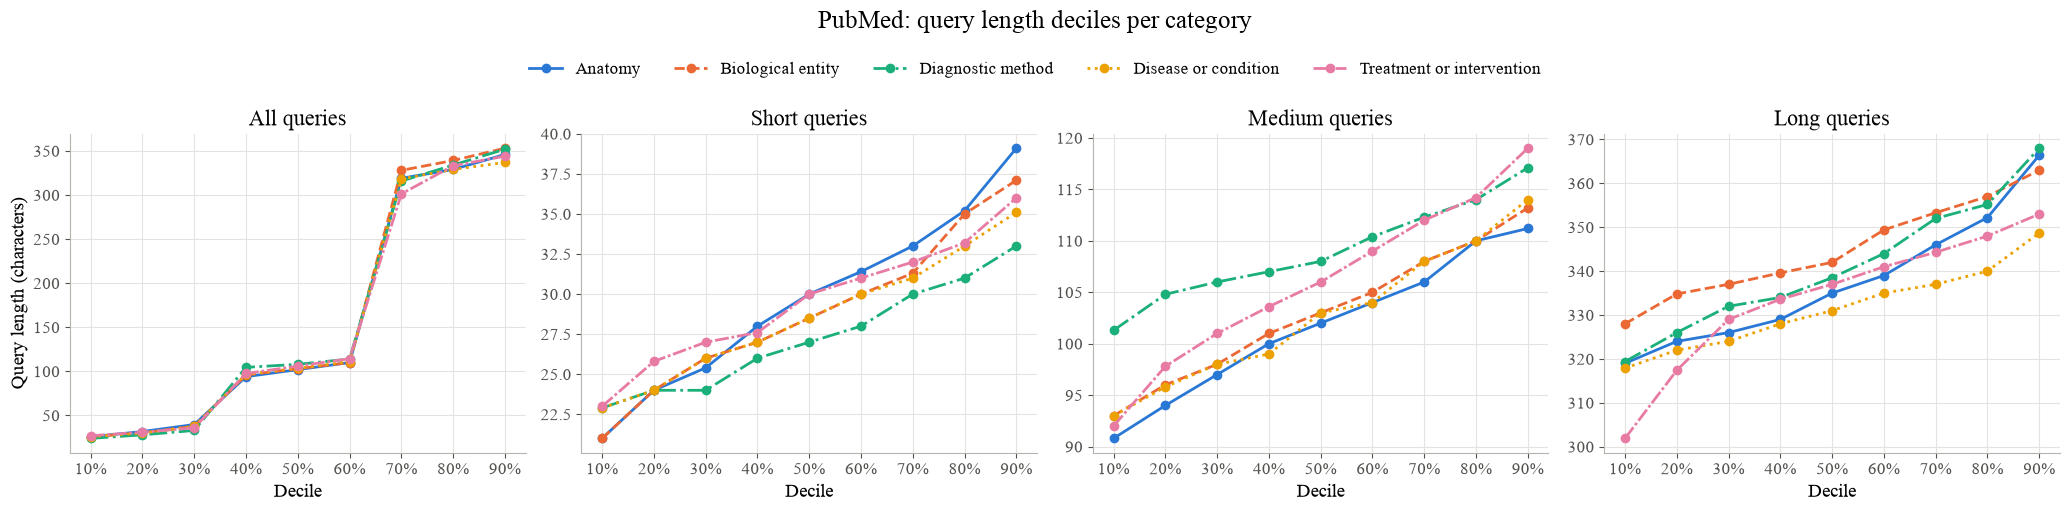

PubMed: query length deciles (characters)


queries  min    p10    p20    p30  \
length bucket category                                                       
All           Anatomy                        360   18   25.8   31.8   39.7   
              Biological entity              360   14   26.0   30.0   37.7   
              Diagnostic method              360   18   24.0   28.0   33.0   
              Disease or condition           350   17   26.0   30.0   37.7   
              Treatment or intervention      360   19   27.0   31.0   36.0   
Short         Anatomy                        120   18   21.0   24.0   25.4   
              Biological entity              120   14   21.0   24.0   26.0   
              Diagnostic method              120   18   22.9   24.0   24.0   
              Disease or condition           110   17   22.9   24.0   26.0   
              Treatment or intervention      120   19   23.0   25.8   27.0   
Medium        Anatomy                        120   83   90.8   94.0   97.0   
              Biological entity              120   86   93.0   96.0   98.0   
              Diagnostic method              120   85  101.3  104.8  106.0   
              Disease or condition           120   89   93.0   95.8   98.0   
              Treatment or intervention      120   81   92.0   97.8  101.0   
Long          Anatomy                        120  309  319.0  324.0  326.0   
              Biological entity              120  319  328.0  334.8  337.0   
              Diagnostic method              120  304  319.4  326.0  332.0   
              Disease or condition           120  307  317.9  322.0  324.0   
              Treatment or intervention      120  288  301.9  317.4  329.0   

                                           p40    p50    p60    p70    p80  \
length bucket category                                                       
All           Anatomy                     94.0  102.0  110.0  319.0  329.0   
              Biological entity           96.0  103.0  110.0  328.0  339.2   
              Diagnostic method          104.6  108.0  114.0  315.8  334.0   
              Disease or condition        96.6  103.5  111.0  318.3  329.0   
              Treatment or intervention   97.6  106.0  114.4  301.3  333.2   
Short         Anatomy                     28.0   30.0   31.4   33.0   35.2   
              Biological entity           27.0   28.5   30.0   31.3   35.0   
              Diagnostic method           26.0   27.0   28.0   30.0   31.0   
              Disease or condition        27.0   28.5   30.0   31.0   33.0   
              Treatment or intervention   27.6   30.0   31.0   32.0   33.2   
Medium        Anatomy                    100.0  102.0  104.0  106.0  110.0   
              Biological entity          101.0  103.0  105.0  108.0  110.0   
              Diagnostic method          107.0  108.0  110.4  112.3  114.0   
              Disease or condition        99.0  103.0  104.0  108.0  110.0   
              Treatment or intervention  103.6  106.0  109.0  112.0  114.2   
Long          Anatomy                    329.0  335.0  339.0  346.0  352.2   
              Biological entity          339.6  342.0  349.4  353.3  357.0   
              Diagnostic method          334.0  338.5  344.0  352.0  355.2   
              Disease or condition       328.0  331.0  335.0  337.0  340.0   
              Treatment or intervention  333.6  337.0  341.0  344.3  348.0   

                                           p90  max  
length bucket category                               
All           Anatomy                    346.0  403  
              Biological entity          353.1  370  
              Diagnostic method          352.0  376  
              Disease or condition       337.0  369  
              Treatment or intervention  344.1  363  
Short         Anatomy                     39.1   48  
              Biological entity           37.1   42  
              Diagnostic method           33.0   39  
              Disease or condition        35.1   43  
             

In [3]:
def decile_table(frame: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for bucket in ("All",) + LENGTH_BUCKETS:
        panel = frame if bucket == "All" else frame[frame["length"] == bucket]
        for category, group in panel.groupby("category"):
            lengths = group["query_length_chars"]
            row = {"length bucket": bucket, "category": category, "queries": len(lengths), "min": lengths.min()}
            row.update({f"p{d}": np.percentile(lengths, d) for d in DECILES})
            row["max"] = lengths.max()
            rows.append(row)
    return pd.DataFrame(rows).set_index(["length bucket", "category"])


def plot_deciles(dataset: str, table: pd.DataFrame) -> None:
    buckets = ("All",) + LENGTH_BUCKETS
    categories = sorted(table.index.get_level_values("category").unique())
    fig, axes = plt.subplots(1, len(buckets), figsize=(5.2 * len(buckets), 4.6))
    for ax, bucket in zip(axes, buckets):
        for index, category in enumerate(categories):
            values = table.loc[(bucket, category), [f"p{d}" for d in DECILES]].to_numpy(float)
            ax.plot(DECILES, values, color=COLOURS[index], linestyle=LINE_STYLES[index],
                    marker="o", markersize=6, linewidth=2, label=category)
        ax.set_title("All queries" if bucket == "All" else f"{bucket} queries")
        ax.set_xticks(DECILES)
        ax.set_xticklabels([f"{d}%" for d in DECILES])
        ax.set_xlabel("Decile")
        style_axis(ax)
    axes[0].set_ylabel("Query length (characters)")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.02),
               ncol=len(categories), frameon=False, fontsize=12)
    fig.suptitle(f"{dataset}: query length deciles per category", fontsize=18, y=1.1)
    fig.tight_layout()
    stem = OUTPUT_DIRECTORY / f"{dataset.lower()}_length_deciles"
    fig.savefig(stem.with_suffix(".png"), dpi=300, bbox_inches="tight")
    fig.savefig(stem.with_suffix(".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(fig)


for dataset, frame in queries.items():
    table = decile_table(frame)
    table.to_csv(OUTPUT_DIRECTORY / f"{dataset.lower()}_length_deciles.csv")
    plot_deciles(dataset, table)
    print(f"{dataset}: query length deciles (characters)")
    display(table.round(1))

## 3. The per-noun feature used by the original white-box model

The original white-box topic model did not use the length distribution above. It used,
for every target noun, the **mean and standard deviation of the lengths of that noun's 30
queries** (`target_probe_query_length_mean` / `_std`). Every noun of a category is asked
with the same 30 templates and the noun adds the same characters to each query, so the
standard deviation depends only on the category's templates. Each point below is one noun.

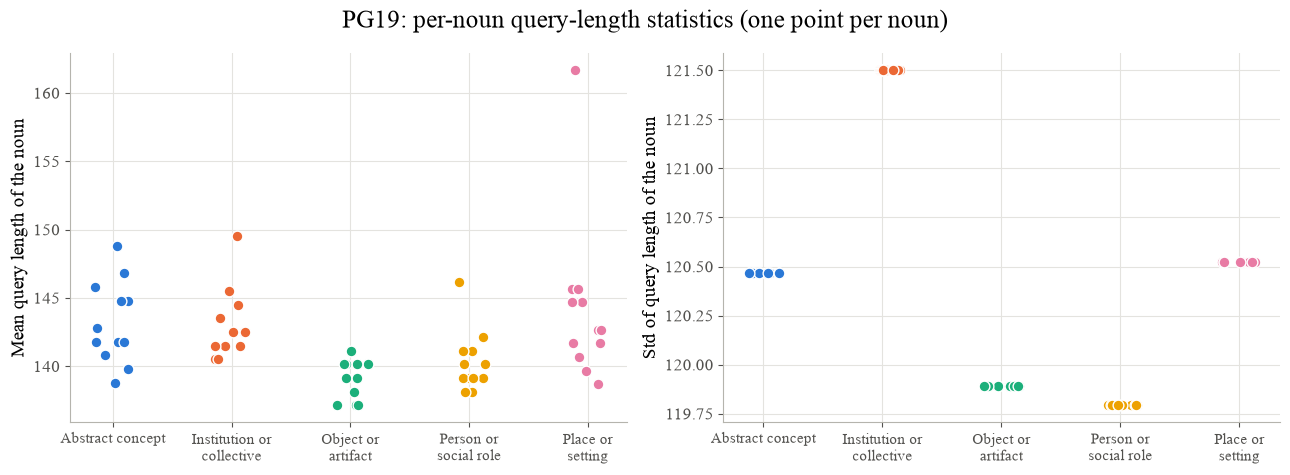

PG19: per-noun std of query length, by category


,std min,std max,distinct std values
category,,,
Abstract concept,120.469,120.469,1
Institution or collective,121.501,121.501,1
Object or artifact,119.890,119.890,1
Person or social role,119.792,119.792,1
Place or setting,120.522,120.522,2


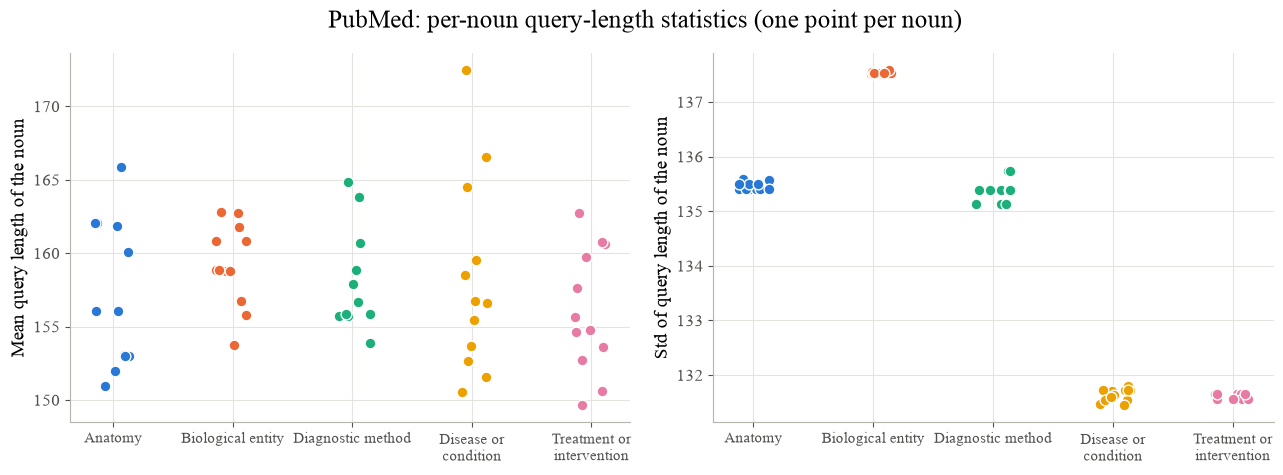

PubMed: per-noun std of query length, by category


,std min,std max,distinct std values
category,,,
Anatomy,135.404,135.595,4
Biological entity,137.506,137.581,5
Diagnostic method,135.140,135.737,3
Disease or condition,131.444,131.798,8
Treatment or intervention,131.553,131.649,2


In [4]:
def noun_length_stats(frame: pd.DataFrame) -> pd.DataFrame:
    parts = frame["query_id"].str.split("__", expand=True)
    noun = parts[0] + "__" + parts[2] + "__" + (parts[3].astype(int) // 10).astype(str)
    return (
        frame.assign(noun=noun)
        .groupby("noun")
        .agg(
            category=("category", "first"),
            probes=("query_length_chars", "size"),
            length_mean=("query_length_chars", "mean"),
            length_std=("query_length_chars", "std"),
        )
    )


def plot_noun_stats(dataset: str, stats: pd.DataFrame) -> None:
    categories = sorted(stats["category"].unique())
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    rng = np.random.default_rng(0)
    for ax, (column, label) in zip(axes, (("length_mean", "Mean query length of the noun"),
                                          ("length_std", "Std of query length of the noun"))):
        for index, category in enumerate(categories):
            values = stats.loc[stats["category"] == category, column].to_numpy()
            jitter = rng.uniform(-0.15, 0.15, len(values))
            ax.scatter(np.full(len(values), index) + jitter, values, s=60, color=COLOURS[index],
                       edgecolor="white", linewidth=1, zorder=3)
        ax.set_xticks(range(len(categories)))
        ax.set_xticklabels([c.replace(" or ", " or\n") for c in categories], fontsize=11)
        ax.set_ylabel(label)
        style_axis(ax)
    fig.suptitle(f"{dataset}: per-noun query-length statistics (one point per noun)", fontsize=18)
    fig.tight_layout()
    stem = OUTPUT_DIRECTORY / f"{dataset.lower()}_noun_length_stats"
    fig.savefig(stem.with_suffix(".png"), dpi=300, bbox_inches="tight")
    fig.savefig(stem.with_suffix(".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(fig)


for dataset, frame in queries.items():
    stats = noun_length_stats(frame)
    stats.to_csv(OUTPUT_DIRECTORY / f"{dataset.lower()}_noun_length_stats.csv")
    plot_noun_stats(dataset, stats)
    summary = stats.groupby("category")["length_std"].agg(["min", "max", "nunique"]).round(3)
    summary.columns = ["std min", "std max", "distinct std values"]
    print(f"{dataset}: per-noun std of query length, by category")
    display(summary)
